# Ejercicio 1. Segmentación de vinos mediante K-Means

En este ejercicio se utilizará el conjunto de datos **Wine**, disponible en Scikit-learn, para agrupar muestras de vino según sus características fisicoquímicas.

Se explorarán y estandarizarán los datos, se probarán diferentes valores de **K** y se evaluarán los agrupamientos para seleccionar un número adecuado de clústeres. Finalmente, se visualizarán e interpretarán los grupos obtenidos.

El análisis utilizará únicamente las variables predictoras **X**, sin emplear las etiquetas originales (`target`) para construir los clústeres.

## 1. Carga y exploración inicial de los datos

Se carga el conjunto de datos Wine y se almacenan sus 13 variables predictoras en la tabla **X**, excluyendo las etiquetas originales. Se consulta el número de registros y variables, y se muestran las primeras cinco filas para reconocer la estructura de los datos.

In [1]:
from sklearn.datasets import load_wine

# Cargar el conjunto de datos como tablas de pandas.
wine = load_wine(as_frame=True)

# Conservar únicamente las variables predictoras.
X = wine.data.copy()

print("Número de registros:", X.shape[0])
print("Número de variables:", X.shape[1])

display(X.head())

Número de registros: 178
Número de variables: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 2. Revisión de la calidad y escala de los datos

Se revisan los tipos de variables y la presencia de valores nulos. También se calculan estadísticas descriptivas para conocer la distribución y los rangos de las características. Esta revisión permitirá determinar si los datos requieren limpieza y justificar su estandarización antes de aplicar K-Means.

In [2]:
# Revisar los tipos de datos y los valores no nulos.
X.info()

# Contar los valores faltantes por variable.
print("\nValores nulos por variable:")
display(X.isnull().sum().to_frame(name="Valores nulos"))

# Consultar estadísticas y comparar las escalas.
print("\nEstadísticas descriptivas:")
display(X.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

,Valores nulos
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## 3. Estandarización de las variables

El conjunto de datos contiene 178 registros y 13 variables numéricas, sin valores nulos, por lo que no se requiere imputar datos faltantes.

Las variables presentan escalas diferentes. Por ejemplo, `proline` tiene valores entre 278 y 1680, mientras que `nonflavanoid_phenols` varía entre 0,13 y 0,66. Como K-Means utiliza distancias, estas diferencias pueden hacer que las variables de mayor escala dominen el agrupamiento.

Por esta razón, se aplica **StandardScaler**, que transforma cada variable para que tenga una media cercana a cero y una desviación estándar de uno. Se conserva la tabla original para interpretar posteriormente las características de los clústeres.

In [3]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Estandarizar las variables para equilibrar sus escalas.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Conservar los nombres de las variables en una nueva tabla.
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

# Verificar la media y desviación estándar de cada variable.
verificacion = pd.DataFrame({
    "Media": X_scaled.mean(),
    "Desviación estándar": X_scaled.std(ddof=0)
})

display(verificacion.round(4))

,Media,Desviación estándar
alcohol,-0.0,1.0
malic_acid,-0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,-0.0,1.0
magnesium,-0.0,1.0
total_phenols,0.0,1.0
flavanoids,-0.0,1.0
nonflavanoid_phenols,0.0,1.0
proanthocyanins,-0.0,1.0
color_intensity,0.0,1.0


## 4. Evaluación de diferentes números de clústeres

Se aplica K-Means sobre los datos estandarizados, probando entre 2 y 6 clústeres. Para cada valor de K se calculan dos indicadores:

- **Inercia:** suma de las distancias al cuadrado de las observaciones al centroide de su grupo. Un valor menor indica grupos más compactos, aunque disminuye naturalmente al aumentar K.
- **Silhouette Score:** evalúa la cohesión y separación de los grupos. Toma valores entre −1 y 1; los valores más altos indican una mejor separación.

Se fija una semilla para facilitar la reproducción de los resultados y se realizan diez inicializaciones por cada valor de K para reducir la dependencia de los centroides iniciales.

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []

# Evaluar entre 2 y 6 clústeres.
for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    resultados.append({
        "K": k,
        "Inercia": modelo.inertia_,
        "Silhouette": silhouette_score(X_scaled, etiquetas)
    })

# Organizar los resultados para compararlos.
resultados_k = pd.DataFrame(resultados)
display(resultados_k.round(4))

,K,Inercia,Silhouette
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.4283,0.2602
3,5,1109.5127,0.2016
4,6,1046.0023,0.2372


## 5. Método del codo y comparación con Silhouette

Se representa la inercia para identificar un posible “codo”: un punto a partir del cual aumentar el número de clústeres produce mejoras menores en la compactación de los grupos.

También se grafica el Silhouette Score para comparar la separación de los agrupamientos. Entre las configuraciones evaluadas, K = 3 obtiene el mayor valor, con aproximadamente 0,2849. Este resultado favorece tres clústeres, aunque indica que la separación no es fuerte.

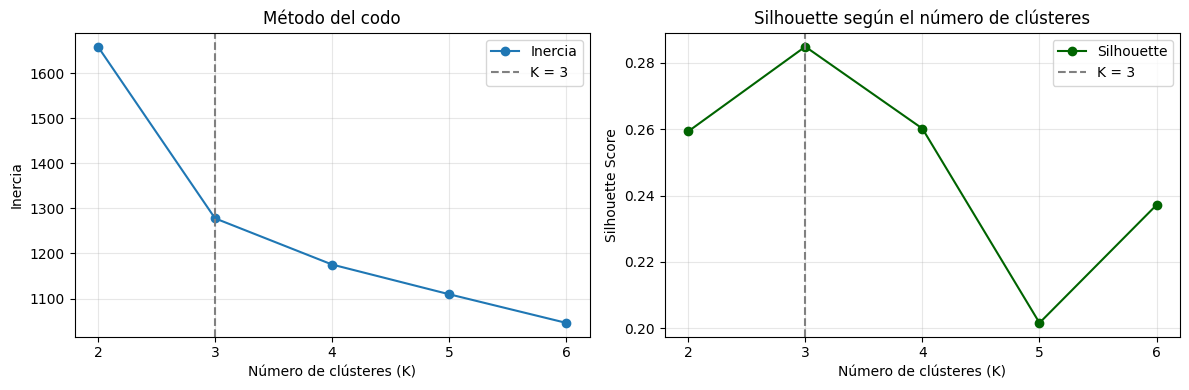

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Método del codo.
axes[0].plot(
    resultados_k["K"], resultados_k["Inercia"],
    marker="o", label="Inercia"
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clústeres (K)")
axes[0].set_ylabel("Inercia")

# Comparación del Silhouette Score.
axes[1].plot(
    resultados_k["K"], resultados_k["Silhouette"],
    marker="o", color="darkgreen", label="Silhouette"
)
axes[1].set_title("Silhouette según el número de clústeres")
axes[1].set_xlabel("Número de clústeres (K)")
axes[1].set_ylabel("Silhouette Score")

for ax in axes:
    ax.set_xticks(resultados_k["K"])
    ax.axvline(3, color="gray", linestyle="--", label="K = 3")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Selección del modelo y evaluación final

Se seleccionan **tres clústeres**. En la gráfica del método del codo, la inercia disminuye de 1658,7589 a 1277,9285 al pasar de K = 2 a K = 3. A partir de ese punto, las reducciones son menores, lo que sugiere un codo en K = 3.

Esta elección coincide con el mayor Silhouette Score obtenido entre los valores evaluados: **0,2849**. Sin embargo, este valor indica que los grupos no presentan una separación fuerte.

Se entrena el modelo definitivo y se evalúa mediante tres métricas: **Silhouette** y **Calinski-Harabasz**, cuyos valores mayores indican mejores agrupamientos, y **Davies-Bouldin**, donde los valores menores son preferibles. Estas métricas se interpretan en conjunto y sobre los mismos datos.

In [6]:
from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score
)

# Entrenar el modelo definitivo con tres clústeres.
modelo_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_kmeans = modelo_final.fit_predict(X_scaled)

# Evaluar los grupos en el espacio estandarizado.
metricas_kmeans = pd.DataFrame([{
    "K": 3,
    "Silhouette": silhouette_score(X_scaled, clusters_kmeans),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, clusters_kmeans),
    "Calinski-Harabasz": calinski_harabasz_score(
        X_scaled, clusters_kmeans
    )
}])

display(metricas_kmeans.round(4))

,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,3,0.2849,1.3892,70.94


## 7. Visualización de los clústeres mediante PCA

Se aplica un análisis de componentes principales (**PCA**) para representar en dos dimensiones los datos estandarizados, que originalmente tienen 13 variables.

Cada punto representa una muestra de vino y su color indica el clúster asignado por K-Means. PCA se utiliza únicamente para visualizar: el agrupamiento y las métricas se calcularon con las 13 variables estandarizadas.

Se muestra también el porcentaje de varianza explicada por los dos componentes, para reconocer cuánta información conserva la representación.

Varianza explicada por los dos componentes: 55.41%


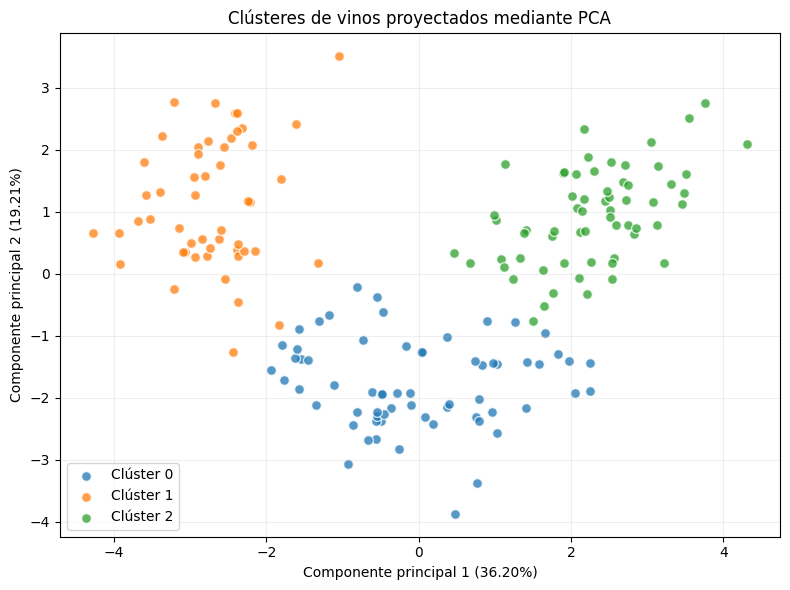

In [7]:
from sklearn.decomposition import PCA

# Proyectar los datos en dos dimensiones solo para visualizarlos.
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)

varianza = pca.explained_variance_ratio_ * 100
print(f"Varianza explicada por los dos componentes: {varianza.sum():.2f}%")

# Representar los grupos que ya asignó K-Means.
fig, ax = plt.subplots(figsize=(8, 6))
colores = ["tab:blue", "tab:orange", "tab:green"]

for grupo, color in enumerate(colores):
    seleccion = clusters_kmeans == grupo
    ax.scatter(
        X_pca[seleccion, 0],
        X_pca[seleccion, 1],
        color=color,
        label=f"Clúster {grupo}",
        alpha=0.75,
        edgecolors="white",
        s=50
    )

ax.set_title("Clústeres de vinos proyectados mediante PCA")
ax.set_xlabel(f"Componente principal 1 ({varianza[0]:.2f}%)")
ax.set_ylabel(f"Componente principal 2 ({varianza[1]:.2f}%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## 8. Caracterización de los clústeres

La visualización mediante PCA conserva el 55,41 % de la varianza total. Aunque permite distinguir los tres grupos, no representa toda la información utilizada por K-Means y debe interpretarse junto con las métricas.

Para conocer las características de cada clúster, se calcula su número de muestras y el promedio de las variables en sus escalas originales. Esto permite describir los grupos mediante características fisicoquímicas, en lugar de limitarse a su posición en la gráfica.

Los números de los clústeres son identificadores arbitrarios: no indican

In [8]:
# Copiar los datos originales y añadir el grupo de cada muestra.
datos_clusters = X.copy()
datos_clusters["Cluster"] = clusters_kmeans

# Contar las muestras de cada grupo.
tamanos = (
    datos_clusters.groupby("Cluster")
    .size()
    .to_frame(name="Número de muestras")
)

print("Tamaño de los clústeres:")
display(tamanos)

# Calcular los promedios en las escalas originales.
perfiles = datos_clusters.groupby("Cluster")[X.columns].mean()

print("\nPromedios por variable y clúster:")
display(perfiles.T.round(3))

Tamaño de los clústeres:


,Número de muestras
Cluster,
0,65
1,51
2,62



Promedios por variable y clúster:


Cluster,0,1,2
alcohol,12.251,13.134,13.677
malic_acid,1.897,3.307,1.998
ash,2.231,2.418,2.466
alcalinity_of_ash,20.063,21.241,17.463
magnesium,92.738,98.667,107.968
total_phenols,2.248,1.684,2.848
flavanoids,2.050,0.819,3.003
nonflavanoid_phenols,0.358,0.452,0.292
proanthocyanins,1.624,1.146,1.922
color_intensity,2.973,7.235,5.454


## 9. Interpretación de los resultados y conclusiones

K-Means distribuyó las 178 muestras en tres clústeres con características fisicoquímicas diferentes. Las siguientes comparaciones corresponden a los promedios de cada grupo:

- **Clúster 0 — 65 muestras:** presenta los menores valores de alcohol (12,251), intensidad de color (2,973) y prolina (510,169). Se caracteriza por una menor intensidad de color y un menor contenido de alcohol respecto a los otros grupos.
- **Clúster 1 — 51 muestras:** registra los mayores valores de ácido málico (3,307) e intensidad de color (7,235), junto con los menores promedios de flavonoides (0,819) y fenoles totales (1,684).
- **Clúster 2 — 62 muestras:** presenta los mayores promedios de alcohol (13,677), fenoles totales (2,848), flavonoides (3,003) y prolina (1100,226).

### Selección del número de clústeres

Se seleccionó **K = 3** porque el método del codo sugiere una disminución de las mejoras a partir de ese punto y el Silhouette Score alcanza su máximo entre las configuraciones evaluadas.

La inercia mide la suma de las distancias al cuadrado de las muestras a sus respectivos centroides. Su reducción indica grupos más compactos, pero no basta para elegir K, ya que disminuye naturalmente al aumentar el número de grupos.

### Separación y limitaciones

El Silhouette Score de **0,2849** indica que la separación de los grupos no es fuerte. Aunque la proyección PCA permite distinguirlos visualmente, conserva solo el **55,41 % de la varianza total**, por lo que no muestra toda la estructura de las 13 variables.

K-Means puede ser sensible a valores atípicos y a la inicialización de los centroides. Además, favorece grupos compactos según la distancia euclídea, lo que puede limitar su capacidad para representar estructuras más complejas. Los resultados tampoco permiten concluir que un grupo tenga vinos de mejor calidad.

### Conclusión

La estandarización permitió equilibrar las escalas de las variables antes del agrupamiento. La solución de tres clústeres permitió identificar perfiles diferenciados principalmente por alcohol, ácido málico, fenoles, flavonoides, intensidad de color y prolina. Estos grupos constituyen una segmentación exploratoria y deben interpretarse considerando la separación limitada observada.